In [1]:
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,)

In [2]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)
print("PyTorch version:", torch.__version__)

Device: mps
PyTorch version: 2.14.1


In [3]:
PROJECT_DIR = Path(
    "/Users/kakulrajput/Documents/Image_Detection"
)

DATASET_DIR = (
    PROJECT_DIR / "data" / "processed" / "image_dataset"
)

MODEL_DIR = PROJECT_DIR / "models"
REPORT_DIR = PROJECT_DIR / "reports"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset exists:", DATASET_DIR.exists())
print("Model directory:", MODEL_DIR)
print("Report directory:", REPORT_DIR)

Dataset exists: True
Model directory: /Users/kakulrajput/Documents/Image_Detection/models
Report directory: /Users/kakulrajput/Documents/Image_Detection/reports


In [4]:
IMAGE_SIZE = 224
BATCH_SIZE = 16
NUM_WORKERS = 0

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_dataset = datasets.ImageFolder(
    DATASET_DIR / "train",
    transform=train_transform,
)

val_dataset = datasets.ImageFolder(
    DATASET_DIR / "val",
    transform=eval_transform,
)

print("Classes:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

assert train_dataset.class_to_idx == {"safe": 0, "unsafe": 1}
assert val_dataset.class_to_idx == {"safe": 0, "unsafe": 1}

Classes: {'safe': 0, 'unsafe': 1}
Training images: 3609
Validation images: 771


In [5]:
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 226
Validation batches: 49


In [6]:
weights = models.MobileNet_V3_Large_Weights.DEFAULT

model = models.mobilenet_v3_large(weights=weights)

num_features = model.classifier[-1].in_features

model.classifier[-1] = nn.Linear(
    num_features,
    2,
)

model = model.to(DEVICE)

print(model.classifier)

Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=2, bias=True)
)


In [7]:
for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print("Trainable parameters:", trainable_parameters)
print("Total parameters:", total_parameters)

Trainable parameters: 1232642
Total parameters: 4204594


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = AdamW(
    model.classifier.parameters(),
    lr=1e-3,
    weight_decay=1e-4,
)

print("Loss function:", criterion)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_training = optimizer is not None

    if is_training:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_labels = []
    all_predictions = []
    all_probabilities = []

    for images, labels in loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):
            logits = model(images)

            loss = criterion(logits, labels)

            if is_training:
                loss.backward()
                optimizer.step()

        probabilities = torch.softmax(logits, dim=1)
        predictions = probabilities.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        all_labels.extend(labels.detach().cpu().tolist())
        all_predictions.extend(predictions.detach().cpu().tolist())
        all_probabilities.extend(
            probabilities[:, 1].detach().cpu().tolist()
        )

    average_loss = total_loss / len(loader.dataset)

    metrics = {
        "loss": average_loss,
        "accuracy": accuracy_score(all_labels, all_predictions),
        "precision": precision_score(
            all_labels, all_predictions, zero_division=0
        ),
        "recall": recall_score(
            all_labels, all_predictions, zero_division=0
        ),
        "f1": f1_score(
            all_labels, all_predictions, zero_division=0
        ),
    }

    return metrics

In [10]:
import copy

EPOCHS = 5

best_val_f1 = -1.0
best_state = None
history = []

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(
        model,
        train_loader,
        criterion,
        optimizer=optimizer,
    )

    val_metrics = run_epoch(
        model,
        val_loader,
        criterion,
        optimizer=None,
    )

    row = {"epoch": epoch}

    row.update({
        f"train_{key}": value
        for key, value in train_metrics.items()
    })

    row.update({
        f"val_{key}": value
        for key, value in val_metrics.items()
    })

    history.append(row)

    print(f"\nEpoch {epoch}/{EPOCHS}")

    print(
        f"Train loss: {train_metrics['loss']:.4f} | "
        f"Train F1: {train_metrics['f1']:.4f}"
    )

    print(
        f"Val loss: {val_metrics['loss']:.4f} | "
        f"Val precision: {val_metrics['precision']:.4f} | "
        f"Val recall: {val_metrics['recall']:.4f} | "
        f"Val F1: {val_metrics['f1']:.4f}"
    )

    if val_metrics["f1"] > best_val_f1:
        best_val_f1 = val_metrics["f1"]
        best_state = copy.deepcopy(model.state_dict())

print("\nBest validation F1:", round(best_val_f1, 4))

/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch 1/5
Train loss: 0.5216 | Train F1: 0.7663
Val loss: 0.4234 | Val precision: 0.8286 | Val recall: 0.7935 | Val F1: 0.8107


/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch 2/5
Train loss: 0.4048 | Train F1: 0.8292
Val loss: 0.4557 | Val precision: 0.8822 | Val recall: 0.7264 | Val F1: 0.7967


/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch 3/5
Train loss: 0.3258 | Train F1: 0.8634
Val loss: 0.4289 | Val precision: 0.8582 | Val recall: 0.8284 | Val F1: 0.8430


/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch 4/5
Train loss: 0.2811 | Train F1: 0.8907
Val loss: 0.5004 | Val precision: 0.7664 | Val recall: 0.8731 | Val F1: 0.8163


/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/Users/kakulrajput/Documents/Image_Detection/venv/lib/python3.14/site-packages/PIL/Image.py:1134: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(



Epoch 5/5
Train loss: 0.2172 | Train F1: 0.9151
Val loss: 0.4637 | Val precision: 0.8529 | Val recall: 0.7935 | Val F1: 0.8222

Best validation F1: 0.843


In [14]:
if best_state is None:
    raise RuntimeError("Training did not produce a model checkpoint.")

model.load_state_dict(best_state)

checkpoint_path = MODEL_DIR / "image_mobilenetv3_baseline.pt"

checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_to_idx": train_dataset.class_to_idx,
    "image_size": IMAGE_SIZE,
    "mean": MEAN,
    "std": STD,
    "best_val_f1": best_val_f1,
    "architecture": "mobilenet_v3_large",
}

torch.save(checkpoint, checkpoint_path)

history_df = pd.DataFrame(history)

history_path = REPORT_DIR / "mobilenetv3_training_history.csv"
history_df.to_csv(history_path, index=False)

print("Best checkpoint saved:", checkpoint_path)
print("Training history saved:", history_path)

Best checkpoint saved: /Users/kakulrajput/Documents/Image_Detection/models/image_mobilenetv3_baseline.pt
Training history saved: /Users/kakulrajput/Documents/Image_Detection/reports/mobilenetv3_training_history.csv


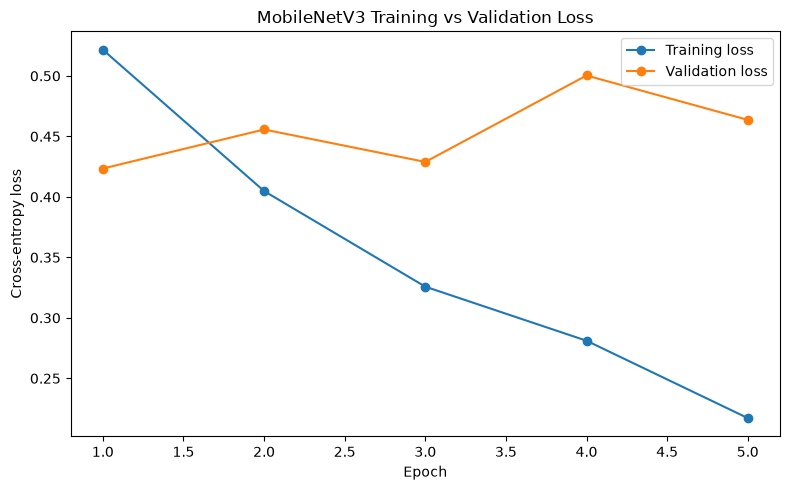

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training loss",
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation loss",
)

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MobileNetV3 Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
checkpoint_path = MODEL_DIR / "image_mobilenetv3_baseline.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

print("Checkpoint keys:", checkpoint.keys())
print("Architecture:", checkpoint["architecture"])
print("Class mapping:", checkpoint["class_to_idx"])
print("Image size:", checkpoint["image_size"])
print("Best validation F1:", checkpoint["best_val_f1"])

Checkpoint keys: dict_keys(['model_state_dict', 'class_to_idx', 'image_size', 'mean', 'std', 'best_val_f1', 'architecture'])
Architecture: mobilenet_v3_large
Class mapping: {'safe': 0, 'unsafe': 1}
Image size: 224
Best validation F1: 0.8430379746835444
